<a href="https://colab.research.google.com/github/ML-HW-SYS/a3-AaronGoldblatt/blob/main/visualizations.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# 1D Convolution on CPU (Numpy)
import numpy as np
import time

M = 4096
N = 128
dtype = 'float32'
a_np = np.random.rand(M).astype(dtype)
w_np = np.random.rand(N).astype(dtype)

start_time = time.time()
b_np = np.convolve(a_np, w_np, mode='full')
end_time = time.time()
print(f"1D Conv Numpy runtime: {(end_time - start_time) * 1000:.3f} ms")


1D Conv Numpy runtime: 0.349 ms


In [2]:
# 1D Convolution on GPU (Torch)

import torch
import time

M = 16384
N = 32
dtype = torch.float32
a_tensor = torch.rand(M, dtype=dtype).to('cuda')
w_tensor = torch.rand(N, dtype=dtype).to('cuda')

start_time = time.time()
b_tensor = torch.conv1d(a_tensor.view(1, 1, -1), w_tensor.view(1, 1, -1))
end_time = time.time()
print(f"1D Conv Torch runtime: {(end_time - start_time) * 1000:.3f} ms")


1D Conv Torch runtime: 583.625 ms


In [3]:
# GEMM on GPU (Torch)

import torch
import time

M = 1024
K = 2048
N = 512
dtype = torch.float32
a_tensor = torch.rand(M, K, dtype=dtype).to('cuda')
w_tensor = torch.rand(K, N, dtype=dtype).to('cuda')

start_time = time.time()
b_tensor = torch.matmul(a_tensor, w_tensor)
end_time = time.time()
print(f"GEMM Torch runtime: {(end_time - start_time) * 1000:.3f} ms")


GEMM Torch runtime: 81.190 ms


In [5]:
# 2D Depthwise Separable Convolution on GPU (Torch)

import torch
import time

B = 3
C = 4
H = 16
W = 32
K = 7
dtype = torch.float32
a_tensor = torch.rand(B, C, H, W, dtype=dtype).to('cuda')

# Depthwise Separable Convolution (with groups=C)
conv = torch.nn.Conv2d(C, C, kernel_size=K, stride=1, padding=K//2, groups=C).to('cuda')

start_time = time.time()
b_tensor = conv(a_tensor)
end_time = time.time()

print(f"2D Depthwise Separable Conv Torch runtime: {(end_time - start_time) * 1000:.3f} ms")


2D Depthwise Separable Conv Torch runtime: 26.027 ms


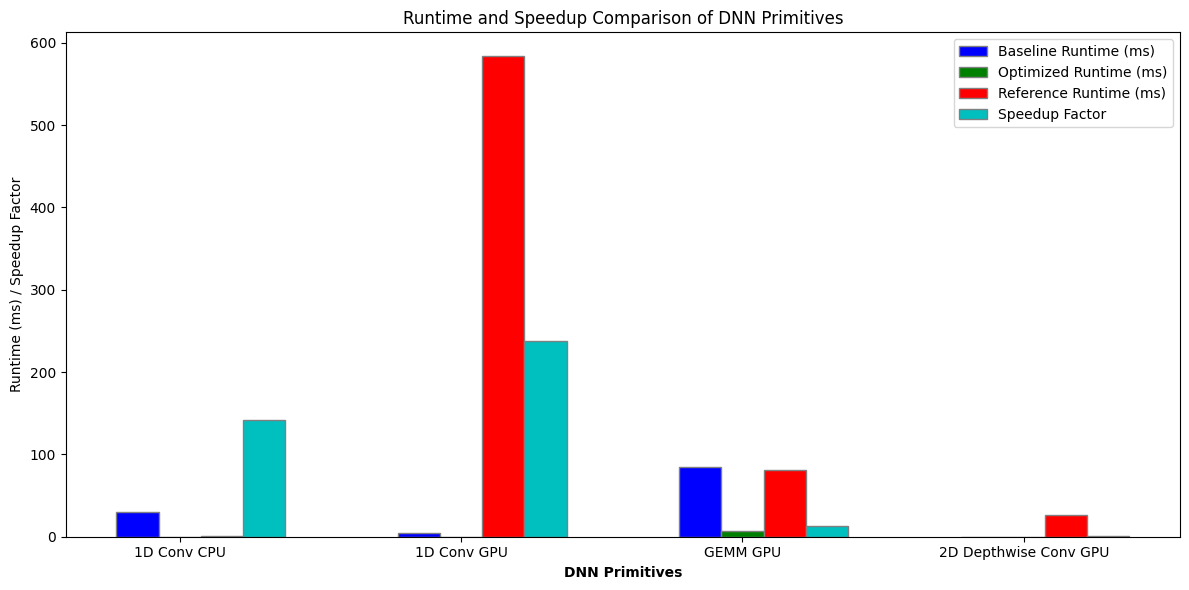

In [7]:
import matplotlib.pyplot as plt
import numpy as np

# Data from your tables
parts = ['1D Conv CPU', '1D Conv GPU', 'GEMM GPU', '2D Depthwise Conv GPU']
baseline_runtimes = [30.24914, 4.233215, 84.486846, 0.124608]
optimized_runtimes = [0.213491, 0.017759, 6.355967, 0.101599]
reference_runtimes = [0.349, 583.625, 81.19, 26.027]
speedup_factors = [141.69, 238.37, 13.29, 1.23]
reference_speedup_factors = [1.63, 32863.6, 12.77, 256.17]

# Bar width
bar_width = 0.15

# Positions of bars on x-axis
r1 = np.arange(len(parts))
r2 = [x + bar_width for x in r1]
r3 = [x + bar_width for x in r2]
r4 = [x + bar_width for x in r3]

# Create the bar chart
plt.figure(figsize=(12, 6))

plt.bar(r1, baseline_runtimes, color='b', width=bar_width, edgecolor='grey', label='Baseline Runtime (ms)')
plt.bar(r2, optimized_runtimes, color='g', width=bar_width, edgecolor='grey', label='Optimized Runtime (ms)')
plt.bar(r3, reference_runtimes, color='r', width=bar_width, edgecolor='grey', label='Reference Runtime (ms)')
plt.bar(r4, speedup_factors, color='c', width=bar_width, edgecolor='grey', label='Speedup Factor')

# Add labels
plt.xlabel('DNN Primitives', fontweight='bold')
plt.xticks([r + bar_width for r in range(len(parts))], parts)
plt.ylabel('Runtime (ms) / Speedup Factor')
plt.title('Runtime and Speedup Comparison of DNN Primitives')

# Add legend
plt.legend()

# Show the plot
plt.tight_layout()
plt.show()

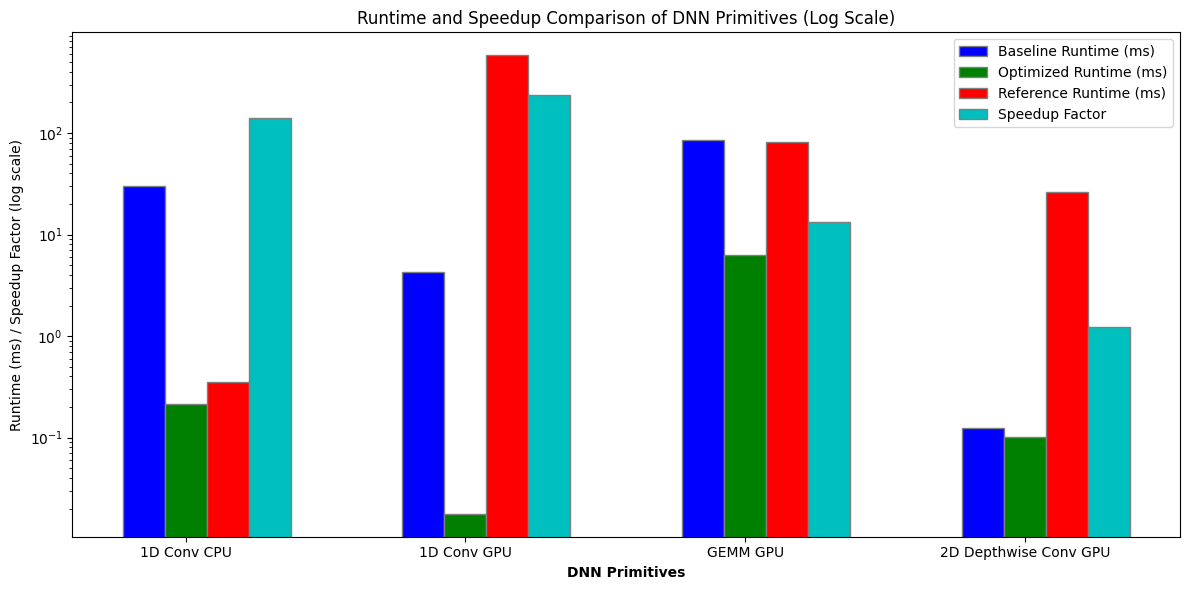

In [6]:
import matplotlib.pyplot as plt
import numpy as np

# Data from your tables
parts = ['1D Conv CPU', '1D Conv GPU', 'GEMM GPU', '2D Depthwise Conv GPU']
baseline_runtimes = [30.24914, 4.233215, 84.486846, 0.124608]
optimized_runtimes = [0.213491, 0.017759, 6.355967, 0.101599]
reference_runtimes = [0.349, 583.625, 81.19, 26.027]
speedup_factors = [141.69, 238.37, 13.29, 1.23]
reference_speedup_factors = [1.63, 32863.6, 12.77, 256.17]

# Bar width
bar_width = 0.15

# Positions of bars on x-axis
r1 = np.arange(len(parts))
r2 = [x + bar_width for x in r1]
r3 = [x + bar_width for x in r2]
r4 = [x + bar_width for x in r3]

# Create the bar chart
plt.figure(figsize=(12, 6))

plt.bar(r1, baseline_runtimes, color='b', width=bar_width, edgecolor='grey', label='Baseline Runtime (ms)')
plt.bar(r2, optimized_runtimes, color='g', width=bar_width, edgecolor='grey', label='Optimized Runtime (ms)')
plt.bar(r3, reference_runtimes, color='r', width=bar_width, edgecolor='grey', label='Reference Runtime (ms)')
plt.bar(r4, speedup_factors, color='c', width=bar_width, edgecolor='grey', label='Speedup Factor')

# Set log scale for y-axis
plt.yscale('log')

# Add labels
plt.xlabel('DNN Primitives', fontweight='bold')
plt.xticks([r + bar_width for r in range(len(parts))], parts)
plt.ylabel('Runtime (ms) / Speedup Factor (log scale)')
plt.title('Runtime and Speedup Comparison of DNN Primitives (Log Scale)')

# Add legend
plt.legend()

# Show the plot
plt.tight_layout()
plt.show()